# MSA CHAMP: Infinium Methylation Screening Array analysis

This notebook is a platform-specific workflow for selected raw IDAT pairs from GEO **GSE264438 / GPL34394**. It is separate from the HumanMethylation27 project in the 27k_champ folder.

**Important:** the ChAMP package documentation limits its IDAT importer to 450K and EPIC, so this notebook does not call champ.import() or champ.load() on MSA data. It uses the MSA-compatible manifest with minfi for import/QC/preprocessing, then limma for a differential probe analysis (DMP) only when a real study contrast is configured. msa_champ is the project name.

GEO reports 284,317 probe rows and SeSAMe v1.22 processing for this platform. GSM8217992 is an *Illumina Control DNA* sample and is included as a small import/QC example only. GEO also notes SNP-probe readings in IDATs were de-identified; do not use them for genetic identity, ancestry, or sex inference.

## Manifest revision

GSE264438 was released in 2024. Use the matching **A1** MSA manifest for the GEO design. Illumina's support page also lists a newer **B1** revision from 2026 whose release notes describe eight removed probes. The notebook uses the Bioconductor IlluminaHumanMethylationMSAmanifest package, built for minfi compatibility from the MSA A1 design. If you download the vendor CSV directly, choose A1 and record its exact filename.

Sources: [GSE264438](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE264438), [GPL34394](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL34394), [GSM8217992](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM8217992), [Illumina MSA manifests](https://support.illumina.com/downloads/infinium-methylation-screening-manifest-files.html), [MSA manifest package](https://bioconductor.org/packages/release/data/annotation/html/IlluminaHumanMethylationMSAmanifest.html), [minfi](https://bioconductor.org/packages/release/bioc/html/minfi.html), [ChAMP manual](https://bioconductor.org/packages/release/bioc/manuals/ChAMP/man/ChAMP.pdf).


## 1. Install and load packages

Open this notebook with the R (MSA workflow) Jupyter kernel. If it is not listed, register IRkernel from an R console as shown in the project README. Use an R version compatible with the Bioconductor release selected by BiocManager. Package installation is a one-time step.


In [1]:
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")

bioc_pkgs <- c(
  "minfi",
  "limma",
  "GEOquery",
  "IlluminaHumanMethylationMSAmanifest",
  "IlluminaHumanMethylationMSAanno.ilm10a1.hg38"
)
missing_bioc <- bioc_pkgs[!vapply(bioc_pkgs, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing_bioc)) BiocManager::install(missing_bioc, ask = FALSE, update = FALSE)
if (!requireNamespace("R.utils", quietly = TRUE)) install.packages("R.utils")
if (!requireNamespace("locfit", quietly = TRUE)) install.packages("locfit")

suppressPackageStartupMessages({
  library(minfi)
  library(limma)
  library(GEOquery)
})


Setting options('download.file.method.GEOquery'='auto')



Setting options('GEOquery.inmemory.gpl'=FALSE)



## 2. Project paths and sample sheet

The checked-in sample-sheet example contains four Illumina Control DNA samples (GSM8217992–GSM8217995) from one array run. Copy it to metadata/sample_sheet.csv and add GSM rows from the same biological study before any differential analysis. If no local copy exists, the notebook falls back to this QC-only example. Use include_in_dmp=TRUE only for samples belonging to the intended contrast. Do not compare unrelated tissues/cell lines as if they were biological replicates.


In [2]:
find_msa_project <- function(start = getwd()) {
  here <- normalizePath(start, winslash = "/", mustWork = TRUE)
  repeat {
    if (file.exists(file.path(here, "msa_champ", "README.md"))) return(file.path(here, "msa_champ"))
    if (basename(here) == "msa_champ" && file.exists(file.path(here, "README.md"))) return(here)
    if (basename(here) == "notebooks" && basename(dirname(here)) == "msa_champ") return(dirname(here))
    parent <- dirname(here)
    if (identical(parent, here)) stop("Could not find msa_champ/. Start Jupyter from this repository or the msa_champ folder.")
    here <- parent
  }
}

PROJECT_DIR <- find_msa_project()
SHEET_PATH <- file.path(PROJECT_DIR, "metadata", "sample_sheet.csv")
if (!file.exists(SHEET_PATH)) {
  SHEET_PATH <- file.path(PROJECT_DIR, "metadata", "sample_sheet_example.csv")
  message("Using the checked-in control example. Copy it to metadata/sample_sheet.csv to set up your cohort.")
}
DATA_DIR <- file.path(PROJECT_DIR, "data")
RAW_DIR <- file.path(DATA_DIR, "raw")
INTERMEDIATE_DIR <- file.path(DATA_DIR, "intermediate")
RESULTS_DIR <- file.path(PROJECT_DIR, "results")
dir.create(RAW_DIR, recursive = TRUE, showWarnings = FALSE)
dir.create(INTERMEDIATE_DIR, recursive = TRUE, showWarnings = FALSE)
dir.create(RESULTS_DIR, recursive = TRUE, showWarnings = FALSE)

sample_sheet <- read.csv(SHEET_PATH, stringsAsFactors = FALSE, na.strings = c("", "NA"))
required_cols <- c("geo_accession", "sample_id", "condition", "include_in_dmp", "pair_id", "batch", "tissue", "description")
if (!all(required_cols %in% names(sample_sheet))) stop("Sample sheet must contain: ", paste(required_cols, collapse = ", "))
if (!nrow(sample_sheet)) stop("Add at least one GEO sample to metadata/sample_sheet.csv.")
if (anyDuplicated(sample_sheet$geo_accession)) stop("Each GEO accession must appear once in the sample sheet.")
if (any(!grepl("^GSM[0-9]+$", sample_sheet$geo_accession))) stop("Check GEO accession format (for example GSM8217992).")
if (anyNA(sample_sheet$sample_id) || anyDuplicated(sample_sheet$sample_id)) stop("sample_id values must be present and unique.")

GSM_IDS <- sample_sheet$geo_accession
DETECTION_P_CUTOFF <- 0.01
MAX_FAILED_PROBE_FRACTION <- 0.01 # exclude probes failing detection in >1% of selected samples
REFERENCE_LEVEL <- "Control"       # set to a level present in included samples
COMPARISON_LEVEL <- "Case"         # set to the comparison level present in included samples
PAIRING_COLUMN <- ""               # optional matched-study column, for example "pair_id"
COVARIATE_COLUMNS <- character()  # optional covariates, for example c("batch", "age")


Using the checked-in control example. Copy it to metadata/sample_sheet.csv to set up your cohort.



## 3. Fetch only the selected GEO IDAT pairs

GEOquery reads each selected GSM record to obtain its supplementary-file URLs. The notebook downloads only the red/green IDAT pair for each selected accession; it does not download the series-wide archive.


In [3]:
for (gsm in GSM_IDS) {
  message("Checking local GEO files for ", gsm)
  gsm_dir <- file.path(RAW_DIR, gsm)
  dir.create(gsm_dir, recursive = TRUE, showWarnings = FALSE)
  compressed <- list.files(gsm_dir, pattern = "_(Red|Grn)\\.idat\\.gz$", full.names = TRUE, recursive = TRUE)
  if (length(compressed) != 2L) {
    message("Fetching IDAT pair for ", gsm, " from GEO")
    gsm_record <- GEOquery::getGEO(gsm, GSEMatrix = FALSE)
    supp_urls <- GEOquery::Meta(gsm_record)$supplementary_file
    supp_urls <- supp_urls[grepl("_(Red|Grn)\\.idat\\.gz$", supp_urls)]
    if (length(supp_urls) != 2L) stop("Expected two GEO IDAT URLs for ", gsm, "; found ", length(supp_urls), ".")
    for (url in supp_urls) {
      dest <- file.path(gsm_dir, basename(url))
      if (!file.exists(dest)) utils::download.file(url, destfile = dest, mode = "wb", method = "libcurl")
    }
    compressed <- list.files(gsm_dir, pattern = "_(Red|Grn)\\.idat\\.gz$", full.names = TRUE, recursive = TRUE)
  }
  if (length(compressed) != 2L) stop(gsm, " should have exactly two compressed IDATs; found ", length(compressed), ". Check its GEO record.")
  for (f in compressed) {
    out <- sub("\\.gz$", "", f)
    if (!file.exists(out)) R.utils::gunzip(f, destname = out, remove = FALSE, overwrite = TRUE)
  }
}

pair_files <- lapply(GSM_IDS, function(gsm) {
  gsm_dir <- file.path(RAW_DIR, gsm)
  red <- list.files(gsm_dir, pattern = "_Red\\.idat$", full.names = TRUE, recursive = TRUE)
  grn <- list.files(gsm_dir, pattern = "_Grn\\.idat$", full.names = TRUE, recursive = TRUE)
  if (length(red) != 1L || length(grn) != 1L) stop(gsm, " needs exactly one red and one green IDAT.")
  red_base <- sub("_Red\\.idat$", "", red)
  grn_base <- sub("_Grn\\.idat$", "", grn)
  if (!identical(red_base, grn_base)) stop(gsm, " red and green IDAT basenames do not match.")
  data.frame(geo_accession = gsm, Basename = red_base, stringsAsFactors = FALSE)
})
idat_index <- do.call(rbind, pair_files)
targets <- merge(sample_sheet, idat_index, by = "geo_accession", all.x = TRUE, sort = FALSE)
targets <- targets[match(sample_sheet$geo_accession, targets$geo_accession), , drop = FALSE]
if (anyNA(targets$Basename)) stop("No red/green IDAT pair found for: ", paste(targets$geo_accession[is.na(targets$Basename)], collapse = ", "))
rownames(targets) <- targets$sample_id
targets$include_in_dmp <- toupper(as.character(targets$include_in_dmp)) %in% c("TRUE", "T", "YES", "Y", "1")

all_idats <- unlist(lapply(GSM_IDS, function(gsm) list.files(file.path(RAW_DIR, gsm), pattern = "_(Red|Grn)\\.idat$", full.names = TRUE, recursive = TRUE)))
data.frame(filename = basename(all_idats), size_bytes = file.info(all_idats)$size, modified_at = file.info(all_idats)$mtime, row.names = NULL)


Checking local GEO files for GSM8217992



Checking local GEO files for GSM8217993



Checking local GEO files for GSM8217994



Checking local GEO files for GSM8217995



,size,mtime
,<dbl>,<dttm>
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217992/GSM8217992_207760740037_R01C01_Grn.idat,5000744,2026-11-24 11:58:34
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217992/GSM8217992_207760740037_R01C01_Red.idat,5000744,2026-11-24 11:58:34
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217993/GSM8217993_207760740037_R03C01_Grn.idat,5000744,2026-11-24 12:27:14
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217993/GSM8217993_207760740037_R03C01_Red.idat,5000744,2026-11-24 12:27:14
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217994/GSM8217994_207760740037_R05C01_Grn.idat,5000744,2026-11-24 12:27:20
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217994/GSM8217994_207760740037_R05C01_Red.idat,5000744,2026-11-24 12:27:20
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217995/GSM8217995_207760740037_R07C01_Grn.idat,5000744,2026-11-24 12:27:26
C:/Users/surbh/OneDrive - University of Vermont/Documents/ChatGPT/Champ/msa_champ/data/raw/GSM8217995/GSM8217995_207760740037_R07C01_Red.idat,5000744,2026-11-24 12:27:26


## 4. Import with the MSA manifest

The MSA platform must be set explicitly because minfi does not automatically identify this array. The official Illumina MSA manifest and matching A1 hg38 annotation package are installed; minfi uses the annotation label ilm10a1.hg38.


In [4]:
rgSet <- read.metharray.exp(targets = targets, force = TRUE, verbose = TRUE)
sampleNames(rgSet) <- targets$sample_id
annotation(rgSet) <- c(array = "IlluminaHumanMethylationMSA", annotation = "ilm10a1.hg38")

stopifnot(ncol(rgSet) == nrow(sample_sheet))
cat("Imported samples:", ncol(rgSet), "\n")
cat("Probe addresses in IDAT RG set:", nrow(rgSet), "\n")
print(pData(rgSet)[, intersect(c("sample_id", "geo_accession", "condition", "tissue"), names(pData(rgSet))), drop = FALSE])


[read.metharray] Reading GSM8217992_207760740037_R01C01_Grn.idat



[read.metharray] Reading GSM8217993_207760740037_R03C01_Grn.idat



[read.metharray] Reading GSM8217994_207760740037_R05C01_Grn.idat



[read.metharray] Reading GSM8217995_207760740037_R07C01_Grn.idat



[read.metharray] Reading GSM8217992_207760740037_R01C01_Red.idat



[read.metharray] Reading GSM8217993_207760740037_R03C01_Red.idat



... (6 outputs left out)

done in 1.1 seconds



Imported samples: 4 


Probe addresses in IDAT RG set: 384497 


DataFrame with 4 rows and 4 columns
             sample_id geo_accession   condition        tissue
           <character>   <character> <character>   <character>
GSM8217992  GSM8217992    GSM8217992     Control cell line DNA
GSM8217993  GSM8217993    GSM8217993     Control cell line DNA
GSM8217994  GSM8217994    GSM8217994     Control cell line DNA
GSM8217995  GSM8217995    GSM8217995     Control cell line DNA


## 5. Sample-level QC and detection filtering

The following checks report QC metrics; they do not automatically remove samples. Review flagged samples before proceeding. Sample QC uses noob-corrected methylated/unmethylated signals, while detection filtering is calculated from raw IDATs, then applied to both beta and M-value matrices.


Loading required package: IlluminaHumanMethylationMSAmanifest



Loading required package: IlluminaHumanMethylationMSAanno.ilm10a1.hg38



[dyeCorrection] Applying R/G ratio flip to fix dye bias



,sample_id,fraction_probes_detection_p_above_cutoff,cutoff
,<chr>,<dbl>,<dbl>
GSM8217992,GSM8217992,0.02708052,0.01
GSM8217993,GSM8217993,0.02746130,0.01
GSM8217994,GSM8217994,0.05644948,0.01
GSM8217995,GSM8217995,0.06208953,0.01


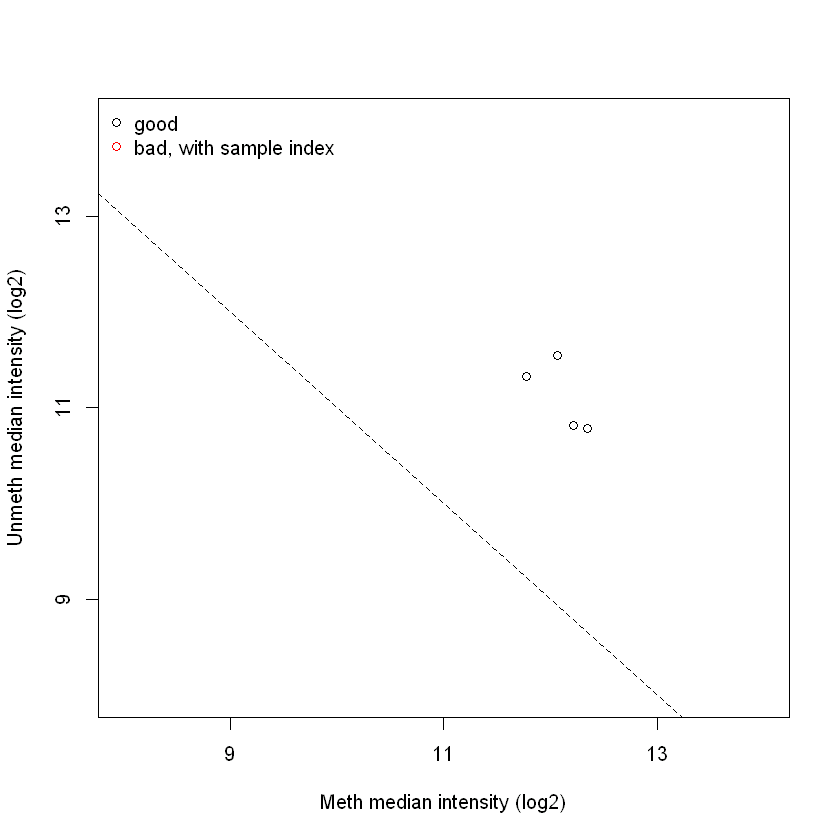

In [5]:
mSet <- preprocessNoob(rgSet, dyeCorr = TRUE, verbose = TRUE)
meth_median <- matrixStats::colMedians(getMeth(mSet), na.rm = TRUE)
unmeth_median <- matrixStats::colMedians(getUnmeth(mSet), na.rm = TRUE)
qc <- data.frame(mMed = log2(meth_median), uMed = log2(unmeth_median))
rownames(qc) <- sampleNames(mSet)
write.csv(qc, file.path(RESULTS_DIR, "sample_qc.csv"), row.names = TRUE)
plotQC(qc)

detP <- detectionP(rgSet)
failed_fraction <- colMeans(detP > DETECTION_P_CUTOFF, na.rm = TRUE)
qc_detection <- data.frame(
  sample_id = colnames(detP),
  fraction_probes_detection_p_above_cutoff = failed_fraction,
  cutoff = DETECTION_P_CUTOFF
)
write.csv(qc_detection, file.path(RESULTS_DIR, "detection_qc.csv"), row.names = FALSE)
qc_detection


## 6. Noob preprocessing and methylation matrices

The noob-corrected MethylSet was calculated in the previous section. GEO's public processed matrices were produced with SeSAMe v1.22, so results from this notebook are a separate preprocessing branch and should not be treated as numerically identical. The official A1 manifest is retained via the installed minfi-compatible manifest package; do not substitute an EPIC/450K probe list.


In [6]:
beta <- getBeta(mSet)
m_values <- getM(mSet)

stopifnot(identical(colnames(beta), targets$sample_id))
detP_index <- match(rownames(beta), rownames(detP))
if (anyNA(detP_index)) stop("Detection p-values are missing for one or more methylation probes.")
detP_beta <- detP[detP_index, , drop = FALSE]
probe_pass <- rowMeans(detP_beta > DETECTION_P_CUTOFF, na.rm = TRUE) <= MAX_FAILED_PROBE_FRACTION
beta_filt <- beta[probe_pass, , drop = FALSE]
m_filt <- m_values[probe_pass, , drop = FALSE]

cat("Probe count before detection filter:", nrow(beta), "\n")
cat("Probe count after detection filter:", nrow(beta_filt), "\n")
write.csv(data.frame(sample_id = names(failed_fraction), failed_probe_fraction = failed_fraction),
          file.path(RESULTS_DIR, "sample_detection_summary.csv"), row.names = FALSE)
saveRDS(beta_filt, file.path(INTERMEDIATE_DIR, "beta_noob_detection_filtered.rds"), compress = "xz")
saveRDS(m_filt, file.path(INTERMEDIATE_DIR, "m_noob_detection_filtered.rds"), compress = "xz")


Probe count before detection filter: 277442 


Probe count after detection filter: 255184 


## 7. Visual QC


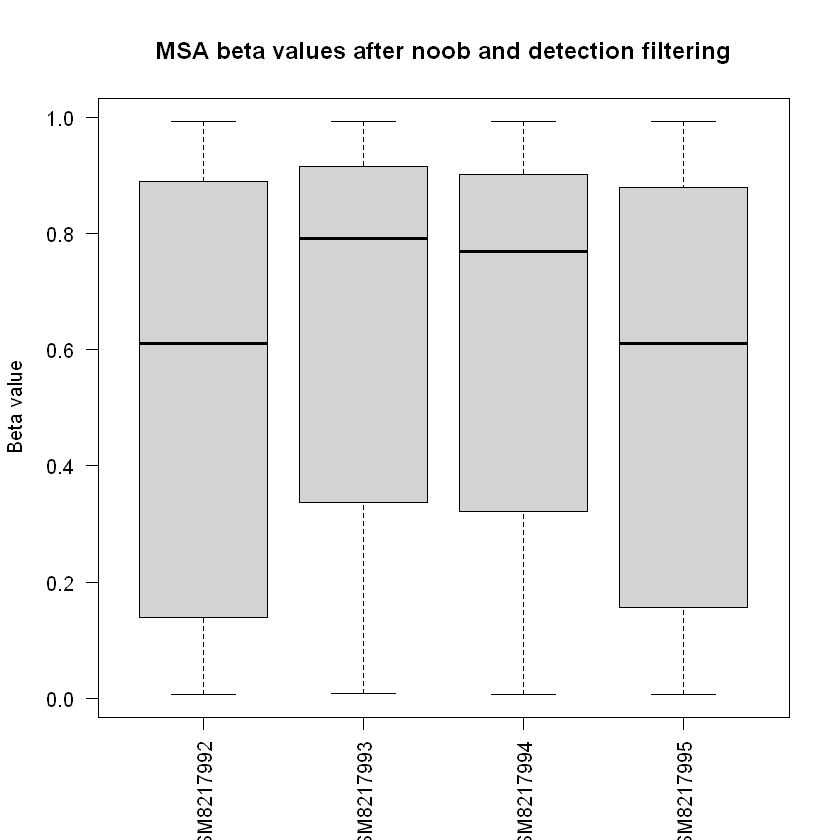

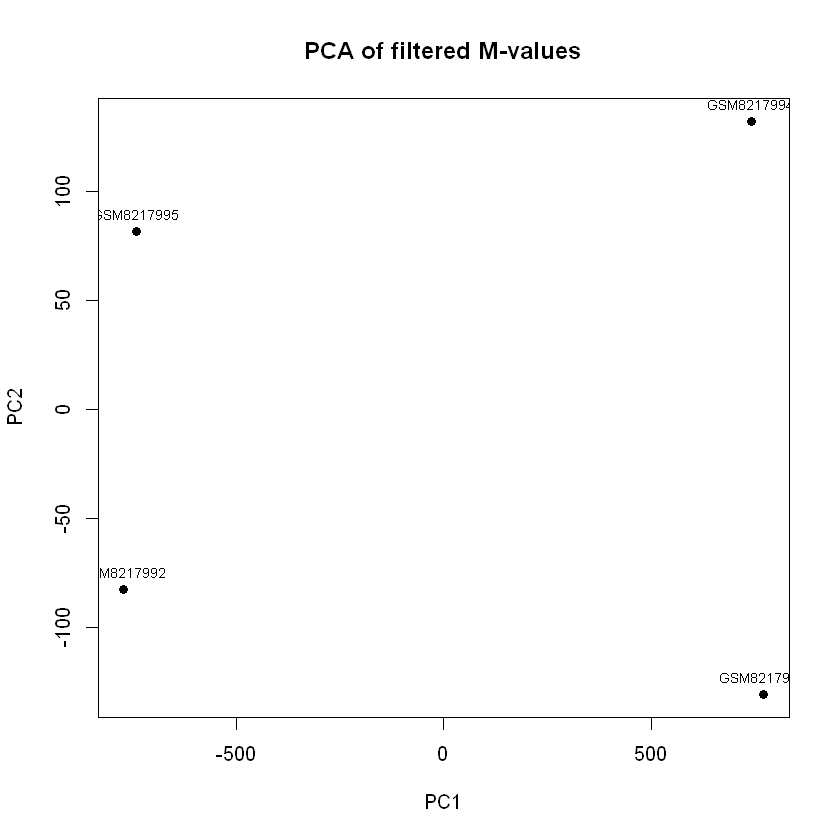

In [7]:
boxplot(beta_filt, las = 2, outline = FALSE, ylab = "Beta value", main = "MSA beta values after noob and detection filtering")
if (ncol(m_filt) >= 2L) {
  finite_probe <- rowSums(!is.finite(m_filt)) == 0L
  if (sum(finite_probe) < 2L) {
    message("PCA skipped: fewer than two probes have finite M-values across all selected samples.")
  } else {
    pca <- prcomp(t(m_filt[finite_probe, , drop = FALSE]), center = TRUE, scale. = FALSE)
    pca_df <- data.frame(sample_id = rownames(pca$x), PC1 = pca$x[, 1], PC2 = pca$x[, 2])
    pca_df <- merge(pca_df, targets, by = "sample_id", all.x = TRUE, sort = FALSE)
    plot(pca_df$PC1, pca_df$PC2, xlab = "PC1", ylab = "PC2", pch = 19,
         main = "PCA of filtered M-values")
    text(pca_df$PC1, pca_df$PC2, labels = pca_df$sample_id, pos = 3, cex = 0.7)
  }
} else {
  message("PCA needs at least two samples; this single-sample example is for import/QC only.")
}


## 8. Optional differential methylation at individual probes

The model uses M-values and limma empirical Bayes statistics; the exported table adds the case-minus-reference mean beta difference for interpretation. The model is skipped unless both groups have at least two included samples. Add covariates to the design only when they are present and scientifically justified. A single control IDAT, samples from unrelated tissues, or empty condition labels are not a valid DMP experiment.


In [8]:
meta <- targets[targets$include_in_dmp, , drop = FALSE]
meta$condition <- as.character(meta$condition)
valid_design <- nrow(meta) > 0L && !anyNA(meta$condition) &&
  all(c(REFERENCE_LEVEL, COMPARISON_LEVEL) %in% unique(meta$condition))

if (valid_design) {
  meta$condition <- relevel(factor(meta$condition), ref = REFERENCE_LEVEL)
  group_n <- table(meta$condition)
  valid_design <- length(group_n) == 2L && all(group_n >= 2L)
}

if (!valid_design) {
  message("DMP skipped: include at least two samples in each of the configured reference and comparison conditions.")
} else {
  model_covariates <- unique(c(if (nzchar(PAIRING_COLUMN)) PAIRING_COLUMN, COVARIATE_COLUMNS))
  missing_covariates <- setdiff(model_covariates, names(meta))
  if (length(missing_covariates)) stop("Model covariate(s) missing from sample sheet: ", paste(missing_covariates, collapse = ", "))
  if (length(model_covariates) && anyNA(meta[, model_covariates, drop = FALSE])) stop("Model covariates contain missing values.")
  if (nzchar(PAIRING_COLUMN)) meta[[PAIRING_COLUMN]] <- factor(meta[[PAIRING_COLUMN]])
  design_terms <- c(model_covariates, "condition")
  design <- model.matrix(reformulate(design_terms), data = meta)
  coef_name <- paste0("condition", make.names(COMPARISON_LEVEL))
  if (!coef_name %in% colnames(design)) stop("Could not find comparison coefficient ", coef_name, " in design: ", paste(colnames(design), collapse = ", "))
  fit <- lmFit(m_filt[, meta$sample_id, drop = FALSE], design)
  fit <- eBayes(fit, robust = TRUE)
  dmp <- topTable(fit, coef = coef_name, number = Inf, adjust.method = "BH", sort.by = "P")
  beta_delta <- rowMeans(beta_filt[, meta$sample_id[meta$condition == COMPARISON_LEVEL], drop = FALSE]) -
    rowMeans(beta_filt[, meta$sample_id[meta$condition == REFERENCE_LEVEL], drop = FALSE])
  dmp$delta_beta_comparison_minus_reference <- beta_delta[rownames(dmp)]
  dmp$probe_id <- rownames(dmp)
  dmp <- dmp[, c("probe_id", setdiff(names(dmp), "probe_id"))]
  write.csv(dmp, file.path(RESULTS_DIR, "dmp_limma.csv"), row.names = FALSE)
  head(dmp, 20)
}


DMP skipped: include at least two samples in each of the configured reference and comparison conditions.



## 9. Save provenance

Record package versions, configuration, and selected GSM accessions alongside the outputs. Review the model design, detection threshold, sample exclusions, and manifest revision before using results.


In [9]:
writeLines(capture.output(sessionInfo()), file.path(RESULTS_DIR, "sessionInfo.txt"))
write.csv(targets, file.path(RESULTS_DIR, "analysis_sample_sheet_used.csv"), row.names = FALSE)
writeLines(c(
  "GEO series: GSE264438",
  "Platform: GPL34394 / Infinium Methylation Screening Array",
  "Manifest: MSA A1; minfi-compatible IlluminaHumanMethylationMSAmanifest package",
  "Annotation: IlluminaHumanMethylationMSAanno.ilm10a1.hg38 (A1 hg38)",
  "Preprocessing: minfi preprocessNoob(dyeCorr=TRUE)",
  paste("Detection p cutoff:", DETECTION_P_CUTOFF),
  paste("Maximum failed-probe fraction:", MAX_FAILED_PROBE_FRACTION),
  paste("Selected GSMs:", paste(GSM_IDS, collapse = ", ")),
  paste("DMP reference/comparison:", REFERENCE_LEVEL, "vs", COMPARISON_LEVEL),
  paste("Pairing column:", ifelse(nzchar(PAIRING_COLUMN), PAIRING_COLUMN, "none")),
  paste("Additional covariates:", ifelse(length(COVARIATE_COLUMNS), paste(COVARIATE_COLUMNS, collapse = ", "), "none"))
), file.path(RESULTS_DIR, "analysis_provenance.txt"))
